In [1]:
from numpy import dtype
import boto3
import pandas as pd
import os  
from botocore.exceptions import NoCredentialsError
from dotenv import load_dotenv
import io
import numpy as np

In [2]:
load_dotenv()

True

## Camada Bronze criada em AWS S3

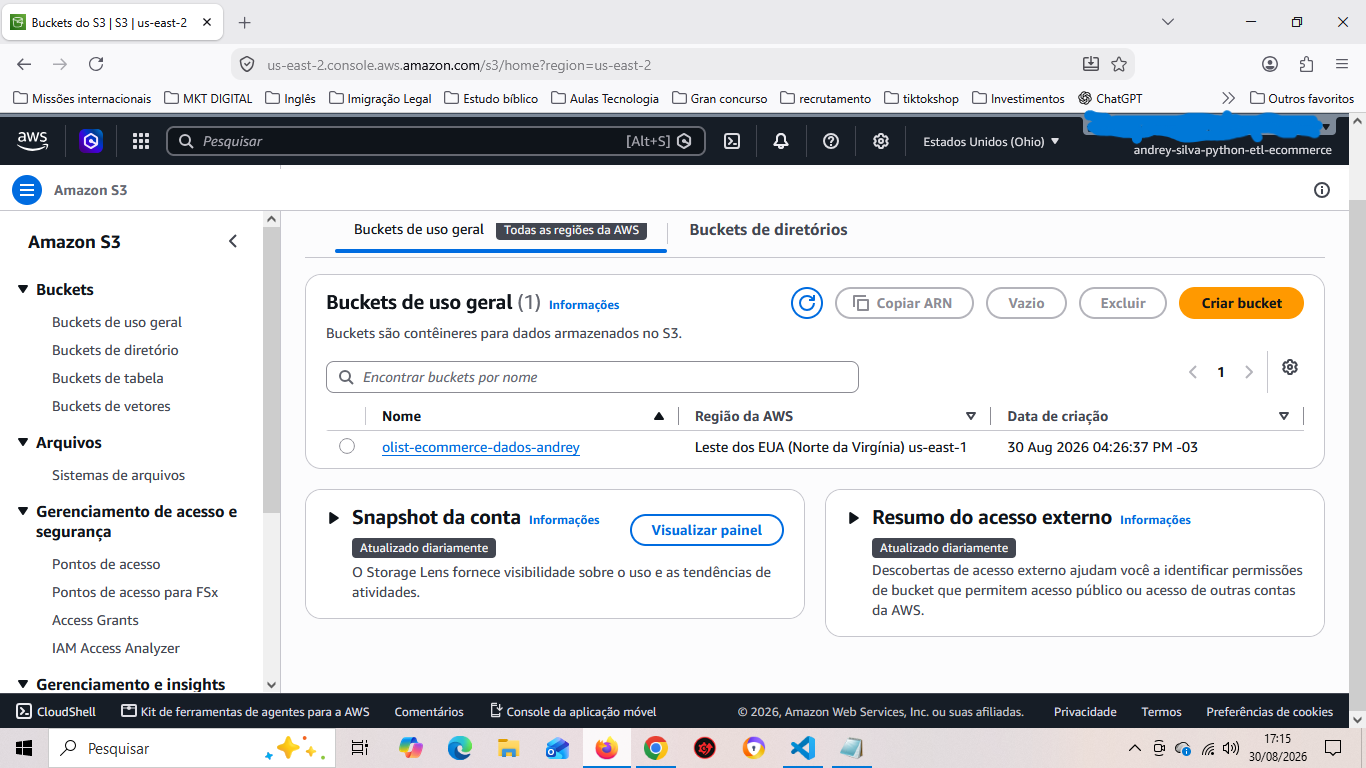

## Conectando ao DataLake AWS bucket S3

In [3]:
# conectar ao S3 da AWS usando dados do .env
s3_client = boto3.client(
    's3',
    aws_access_key_id=os.getenv('AWS_ACCESS_KEY'),
    aws_secret_access_key=os.getenv('AWS_SECRET_KEY'),
    region_name='us-east-1'
    )

## ETL Tabela Dimensão geolocalizacao

In [4]:
#carregar tabela olist_geolocation_dataset do s3 para um dataframe do pandas
obj = s3_client.get_object(Bucket='olist-ecommerce-dados-andrey', Key='olist_geolocation_dataset.csv')
geolocation = pd.read_csv(io.BytesIO(obj['Body'].read()))

In [5]:
#exibir as primeiras linhas do dataframe
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [6]:
# renomear colunas geolocalizacao
geolocation.rename(columns={
    'geolocation_zip_code_prefix': 'zip_code_prefix',
    'geolocation_lat': 'latitude',
    'geolocation_lng': 'longitude',
    'geolocation_city': 'city',
    'geolocation_state': 'state'
}, inplace=True)

In [7]:
#mostrar colunas renomeadas
geolocation.head()  

,zip_code_prefix,latitude,longitude,city,state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [8]:
print(geolocation['city'].unique())
print(geolocation['state'].unique())

<StringArray>
[            'sao paulo',             'são paulo', 'sao bernardo do campo',
               'jundiaí',       'taboão da serra',              'sãopaulo',
                    'sp',            'sa£o paulo',   'sao jose dos campos',
                'osasco',
 ...
       'ipiranga do sul',          'vila langaro',               'ciriaco',
      'floriano peixoto',              'erebango',                'ibiaçá',
  'santa cecilia do sul',               'ciríaco',               'estação',
          'vila lângaro']
Length: 8011, dtype: str
<StringArray>
['SP', 'RN', 'AC', 'RJ', 'ES', 'MG', 'BA', 'SE', 'PE', 'AL', 'PB', 'CE', 'PI',
 'MA', 'PA', 'AP', 'AM', 'RR', 'DF', 'GO', 'RO', 'TO', 'MT', 'MS', 'RS', 'PR',
 'SC']
Length: 27, dtype: str


In [9]:
# Normalizando texto para cidade e estado (remover acentos, caracteres especiais, etc.)
import unicodedata

def normalizar_texto(texto):
    if texto is None:
        return None
    # 1. Converte para minúsculas
    texto = texto.lower()
    # 2. Remove acentos (Normaliza NFD -> remove caracteres de marcação -> converte de volta para UTF-8)
    texto = unicodedata.normalize('NFD', texto)
    texto = "".join(c for c in texto if unicodedata.category(c) != 'Mn')
    # 3. Remove caracteres que não sejam letras ou espaços (limpeza de símbolos)
    import re
    texto = re.sub(r'[^\w\s]', '', texto)
    # 4. Remove espaços extras no início/fim
    return texto.strip()

# Aplicando na coluna cidade
geolocation['city'] = geolocation['city'].apply(normalizar_texto)

# Para o estado, geralmente basta deixar em maiúsculo e sem espaços
geolocation['state'] = geolocation['state'].str.upper().str.strip()

print(geolocation['city'].unique()[:10])

<StringArray>
[            'sao paulo', 'sao bernardo do campo',               'jundiai',
       'taboao da serra',              'saopaulo',                    'sp',
   'sao jose dos campos',                'osasco',           'carapicuiba',
               'barueri']
Length: 10, dtype: str


In [10]:
# verificar tipo de dados em df_geolocalizacao_raw
print(geolocation.dtypes)

zip_code_prefix      int64
latitude           float64
longitude          float64
city                   str
state                  str
dtype: object


In [11]:
# transformar colunas geolocation_lat e geolocation_lng para float
geolocation['latitude'] = pd.to_numeric(geolocation['latitude'], errors='coerce')
geolocation['longitude'] = pd.to_numeric(geolocation['longitude'], errors='coerce')

In [12]:
# transformar cep-prefixo em string para evitar problemas de formatação
geolocation['zip_code_prefix'] = geolocation['zip_code_prefix'].astype(str).str.replace(r'\.0$', '', regex=True).str.zfill(5)

In [13]:
#verificar tipo de dados em geolocalizacao após transformação
print(geolocation.dtypes)

zip_code_prefix        str
latitude           float64
longitude          float64
city                   str
state                  str
dtype: object


In [14]:
# padronizar coluna zip_code_prefix para 5 digitos com zero a esquerda
geolocation['zip_code_prefix'] = geolocation['zip_code_prefix'].astype(str).str.zfill(5)

In [15]:
# 2. Tratar texto de cidade e estado
geolocation['city'] = geolocation['city'].astype(str).str.strip().str.slice(0, 100)
geolocation['state'] = geolocation['state'].astype(str).str.strip().str.upper().str.slice(0, 2)

In [16]:
# verificar dados duplicados em df_geolocalizacao_raw
print(geolocation.duplicated().sum())

279685


In [17]:
# deletar dados duplicados em geolocalizacao pelo zip_code_prefix- exigencia do UNIQUE no data warehouse
geolocation = geolocation.drop_duplicates(subset=['zip_code_prefix'])

In [18]:
# verificar dos dados duplicados em df_geolocalizacao_raw
print(geolocation.duplicated().sum())

0


In [19]:
# verificar dados nulos
print(geolocation.isnull().sum())

zip_code_prefix    0
latitude           0
longitude          0
city               0
state              0
dtype: int64


In [20]:
#verificar linhas vazias
print(geolocation[geolocation.isnull().all(axis=1)].shape[0])

0


In [21]:
geolocation.head()

,zip_code_prefix,latitude,longitude,city,state
0,01037,-23.545621,-46.639292,sao paulo,SP
1,01046,-23.546081,-46.644820,sao paulo,SP
3,01041,-23.544392,-46.639499,sao paulo,SP
4,01035,-23.541578,-46.641607,sao paulo,SP
5,01012,-23.547762,-46.635361,sao paulo,SP


## ETL Tabela Dimensão Cliente

In [22]:
# carregando tabela olist_customers_dataset do s3 para um dataframe do pandas
obj_cliente = s3_client.get_object(Bucket='olist-ecommerce-dados-andrey', Key='olist_customers_dataset.csv')
customers = pd.read_csv(io.BytesIO(obj_cliente['Body'].read()))


In [23]:
# exibir as primeiras linhas do dataframe
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [24]:
# renomear colunas clientes (cliente_id, cliente_unique_id, codigo_postal, cidade, estado)
customers.rename(columns={'customer_zip_code_prefix': 'zip_code_prefix', 'customer_city': 'city', 'customer_state': 'state'}, inplace=True)

In [25]:
customers.head()

,customer_id,customer_unique_id,zip_code_prefix,city,state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [26]:
print(customers['city'].unique())
print(customers['state'].unique())

<StringArray>
[               'franca', 'sao bernardo do campo',             'sao paulo',
       'mogi das cruzes',              'campinas',        'jaragua do sul',
               'timoteo',              'curitiba',        'belo horizonte',
         'montes claros',
 ...
              'balbinos',          'serra bonita',          'venda branca',
           'sanga puita',               'queiroz',                'siriji',
   'natividade da serra',          'monte bonito',            'sao rafael',
     'eugenio de castro']
Length: 4119, dtype: str
<StringArray>
['SP', 'SC', 'MG', 'PR', 'RJ', 'RS', 'PA', 'GO', 'ES', 'BA', 'MA', 'MS', 'CE',
 'DF', 'RN', 'PE', 'MT', 'AM', 'AP', 'AL', 'RO', 'PB', 'TO', 'PI', 'AC', 'SE',
 'RR']
Length: 27, dtype: str


In [27]:
# Normalizar texto para cidade e estado (remover acentos, caracteres especiais, etc.)
customers['city'] = customers['city'].apply(normalizar_texto) 
customers['state'] = customers['state'].apply(normalizar_texto)     

In [28]:
# verificar tipos de dados em clientes
print(customers.dtypes)

customer_id             str
customer_unique_id      str
zip_code_prefix       int64
city                    str
state                   str
dtype: object


In [29]:
customers['zip_code_prefix'] = customers['zip_code_prefix'].astype(str).str.zfill(5)

In [30]:
# mudar tipo de dados de zip_code_prefix para string
customers['zip_code_prefix'] = customers['zip_code_prefix'].astype(str)

In [31]:
print(customers.dtypes)

customer_id           str
customer_unique_id    str
zip_code_prefix       str
city                  str
state                 str
dtype: object


In [32]:
# verificar dados duplicados em clientes
print(customers.duplicated().sum())

0


In [33]:
# verificar dados nulos após tratamento
print(customers.isnull().sum())

customer_id           0
customer_unique_id    0
zip_code_prefix       0
city                  0
state                 0
dtype: int64


In [34]:
# verificar linhas vazias
print(customers[customers.isnull().all(axis=1)].shape[0])

0


In [35]:
# 2. Selecionar apenas as colunas que existem na tabela do DW
customers_dw = customers[[
    'customer_id',
    'customer_unique_id',
    'zip_code_prefix',
    'city',
    'state'
]].copy()

## ETL Tabela Dimensão Vendedores

In [36]:
# carregar tabela olist_sellers_dataset do s3 para um dataframe do pandas
obj_vendedores = s3_client.get_object(Bucket='olist-ecommerce-dados-andrey', Key='olist_sellers_dataset.csv')
sellers = pd.read_csv(io.BytesIO(obj_vendedores['Body'].read()))

In [37]:
# exibir as primeiras linhas do dataframe
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [38]:
# renomear colunas vendedores (vendedor_id, codigo_postal_vendedores, cidade_vendedor, estado_vendedor)
sellers.rename(columns={'seller_zip_code_prefix': 'zip_code_prefix', 'seller_city': 'city', 'seller_state': 'state'}, inplace=True)


In [39]:
# mostrar e excluir caracteres especiais e acentos em cidade_vendedor e estado_vendedor
sellers['city'] = sellers['city'].apply(normalizar_texto)
sellers['state'] = sellers['state'].apply(normalizar_texto)

In [40]:
# verificar tipos de dados em vendedores
print(sellers.dtypes)

seller_id            str
zip_code_prefix    int64
city                 str
state                str
dtype: object


In [41]:
# mudar tipo de dados de codigo_postal para string
sellers['zip_code_prefix'] = (sellers['zip_code_prefix'].astype(str).str.replace(r'\.0$', '', regex=True).str.zfill(5))

In [42]:
# verificar tipos de dados em vendedores
print(sellers.dtypes)

seller_id          str
zip_code_prefix    str
city               str
state              str
dtype: object


In [43]:
# verificar duplicados em vendedores
sellers.duplicated().sum()

np.int64(0)

In [44]:
# verificar dados nulos após tratamento
print(sellers.isnull().sum())

seller_id          0
zip_code_prefix    0
city               0
state              0
dtype: int64


In [45]:
# Verificar linhas vazias
print(sellers[sellers.isnull().all(axis=1)].shape[0])

0


In [46]:
# 2. Selecionando apenas as colunas mapeadas na dim_vendedores
sellers_dw = sellers[[
    'seller_id',
    'zip_code_prefix'
    
]].copy()

## ETL Tab. Dimensão Produtos

In [47]:
# conectar a tabela olist_products_dataset.csv do s3 para um dataframe do pandas
obj_produtos = s3_client.get_object(Bucket='olist-ecommerce-dados-andrey', Key='olist_products_dataset.csv')

In [48]:
# exibir as primeiras linhas do dataframe
products = pd.read_csv(io.BytesIO(obj_produtos['Body'].read()))
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [49]:
# VERIFICAR TIPOS DE dados em produtos
print(products.dtypes)

product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object


In [50]:
# garantir que todos em categoria_produto sejam strings
products['product_category_name'] = products['product_category_name'].astype(str).str.strip().str.slice(0, 100)

In [51]:
# verificar tipos de dados
print(products.dtypes)

product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object


In [52]:
# verificar dados nulos em produtos
print(products.isnull().sum())

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [53]:
# listar somente o que está nas linhas com dados nulos
products[products.isnull().any(axis=1)]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
...,...,...,...,...,...,...,...,...,...
32515,b0a0c5dd78e644373b199380612c350a,NaN,NaN,NaN,NaN,1800.0,30.0,20.0,70.0
32589,10dbe0fbaa2c505123c17fdc34a63c56,NaN,NaN,NaN,NaN,800.0,30.0,10.0,23.0
32616,bd2ada37b58ae94cc838b9c0569fecd8,NaN,NaN,NaN,NaN,200.0,21.0,8.0,16.0
32772,fa51e914046aab32764c41356b9d4ea4,NaN,NaN,NaN,NaN,1300.0,45.0,16.0,45.0


In [54]:
# renomear a coluna product_name_lenght para product_name_length
products.rename(columns={'product_name_lenght': 'product_name_length', 'product_description_lenght': 'product_description_length'}, inplace=True)

In [55]:
products.head()

,product_id,product_category_name,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [56]:
# 1. Garantir que tudo na coluna categoria_produto é tratado como string para podermos limpar
products['product_category_name'] = products['product_category_name'].astype(str).str.strip()

In [57]:
# 2. Transformar textos falsos de "nan" em nulos reais do Python/Pandas
products['product_category_name'] = products['product_category_name'].replace(['nan', 'NaN', 'null', ''], np.nan)

In [58]:
# 3. substitui os nulos reais por "sem categoria" e salvar na coluna
products['product_category_name'] = products['product_category_name'].fillna("sem categoria")

In [59]:
#verificar coluna categoria_produto após tratamento se existe NaN ou nulos
print(products['product_category_name'].isnull().sum())

0


In [60]:
# trocar NaN da coluna tamanho_nome_produto, tamanho_descricao_produto, quantidade_fotos_produto, peso_produto_g, comprimento_produto_cm, altura_produto_cm, largura_produto_cm  por 0
for coluna in ['product_name_length', 'product_description_length', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']:
    if products[coluna].isnull().sum() > 0:
        products[coluna] = products[coluna].fillna(0)

In [61]:
# mostrar dados nulos em produtos após tratamento
print(products.isnull().sum())

product_id                    0
product_category_name         0
product_name_length           0
product_description_length    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64


In [62]:
# Listar todas as colunas que precisam virar inteiro no Data Warehouse
colunas_inteiras = [
    'product_name_length',
    'product_description_length',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

In [63]:
# 1. Converter colunas float64 para inteiros
for col in colunas_inteiras:
    products[col] = products[col].astype('Int64')

In [64]:
# normalizar texto para categoria_produto (remover acentos, caracteres especiais, etc.)
products['product_category_name'] = products['product_category_name'].apply(normalizar_texto)

In [65]:
# verificar duplicados em produtos
print(products.duplicated().sum())

0


In [66]:
# verificar linhas vazias em produtos
print(products[products.isnull().all(axis=1)].shape[0])

0


In [67]:
# 3. Filtrar e selecionar colunas mapeadas no DW
products_dw = products[[
    'product_id',
    'product_category_name',
    'product_name_length',
    'product_description_length',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]].copy()

## ETL Tabela Fato Pedidos

In [68]:
# conectar a tabela olist_orders_dataset.csv do s3 para um dataframe do pandas
obj_pedidos = s3_client.get_object(Bucket='olist-ecommerce-dados-andrey', Key='olist_orders_dataset.csv')

In [69]:
# 1. Armazene o conteúdo em uma variável primeiro
file_content = obj_pedidos['Body'].read()

In [70]:
# 2. Verifique se não está vazio antes de ler com o Pandas
if not file_content:
    print("⚠️ Alerta: O arquivo está completamente vazio no servidor!")
else:
    # 3. Se tiver dados, o Pandas lê sem problemas
    order = pd.read_csv(io.BytesIO(file_content))
    print("Sucesso! Primeiras linhas:")
    print(order.head())

Sucesso! Primeiras linhas:
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26

In [71]:
# verificar tipos de dados em produtos após tratamento
print(order.dtypes)

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object


In [72]:
# mudar tipo de dados de data_pedido, data_aprovacao_pedido, data_entrega_prevista_transportadora, data_entrega_real, data_entrega_prevista_loja para datetime
order['order_purchase_timestamp'] = pd.to_datetime(order['order_purchase_timestamp'], errors='coerce')
order['order_approved_at'] = pd.to_datetime(order['order_approved_at'], errors='coerce')
order['order_delivered_carrier_date'] = pd.to_datetime(order['order_delivered_carrier_date'], errors='coerce')
order['order_delivered_customer_date'] = pd.to_datetime(order['order_delivered_customer_date'], errors='coerce')
order['order_estimated_delivery_date'] = pd.to_datetime(order['order_estimated_delivery_date'], errors='coerce')

In [73]:
# verificar tipos de dados em produtos após tratamento
print(order.dtypes)

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


In [74]:
# verificar dados duplicados em pedidos
print(order.duplicated().sum())

0


In [75]:
# verificar dados nulos em pedidos
print(order.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [76]:
# substituir valores nulos na coluna data_aprovacao_pedido por "pending" - pendente
order['order_approved_at'] = order['order_approved_at'].fillna('pending')

In [77]:
# substituir valores nulos na coluna data_entrega_prevista_a_transportadora por "nao enviado ainda"
order['order_delivered_carrier_date'] = order['order_delivered_carrier_date'].fillna('not yet shipped')

In [78]:
# substituir valores nulos na coluna data_entrega_real por "produto em transito"
order['order_delivered_customer_date'] = order['order_delivered_customer_date'].fillna('product_in_transit')

In [79]:
# verificar dados nulos em pedidos
print(order.isnull().sum())

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64


In [80]:
# verificar quantidade linhas em pedidos
print(f"Quantidade de linhas em pedidos: {len(order)}")

Quantidade de linhas em pedidos: 99441


### Legenda importante
#### Data de aprovação do produto se nulo = não pago ou cancelado
#### Previsão transportadora se nulo = não enviado ainda
#### Data entrega real se nulo = produto em trânsito

In [81]:
# verificar linhas vazias em pedidos
print(order[order.isnull().all(axis=1)].shape[0])

0


## ETL tabela fato Itens

In [82]:
# conectar a tabela olist_order_items_dataset.csv do s3 para um dataframe do pandas
obj_itens = s3_client.get_object(Bucket='olist-ecommerce-dados-andrey', Key='olist_order_items_dataset.csv')

In [83]:
# exibir as primeiras linhas do dataframe itens
item = pd.read_csv(io.BytesIO(obj_itens['Body'].read()))
item.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [84]:
# verificar duplicados em itens_pedido
print(item.duplicated().sum())

0


In [85]:
# verificar dados nulos em itens_pedido
print(item.isnull().sum())

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [86]:
# verificar linhas vazias em itens_pedido
print(item[item.isnull().all(axis=1)].shape[0])

0


In [87]:
# verificar tipos de dados em itens_pedido
print(item.dtypes)

order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object


In [88]:
# mudar tipo de dados de data_limite_envio para datetime
item['shipping_limit_date'] = pd.to_datetime(item['shipping_limit_date'], errors='coerce')
print(item.dtypes)

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object


In [89]:
# verificar quantidade de linhas em itens_pedido
print(f"Quantidade de linhas em itens_pedido: {len(item)}")

Quantidade de linhas em itens_pedido: 112650


### Criando Dataframe Vendas

In [90]:
# 1. Unir Itens e Pedidos pela chave primaria/estrangeira do pedido - dataframe vendas
sales = pd.merge(item, order, on='order_id', how='inner')

In [91]:
# Exibir fato vendas
sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17


In [92]:
# verificar tipo de dados em vendas
print(sales.dtypes)

order_id                                    str
order_item_id                             int64
product_id                                  str
seller_id                                   str
shipping_limit_date              datetime64[us]
price                                   float64
freight_value                           float64
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                        object
order_delivered_carrier_date             object
order_delivered_customer_date            object
order_estimated_delivery_date    datetime64[us]
dtype: object


In [93]:
# mudar tipo de dados data_aprovação_pedido, data_entrega_prevista_transportadora, data_entrega_real, data_entrega_prevista_loja para datetime
sales['order_approved_at'] = pd.to_datetime(sales['order_approved_at'], errors='coerce')
sales['order_delivered_carrier_date'] = pd.to_datetime(sales['order_delivered_carrier_date'], errors='coerce')
sales['order_delivered_customer_date'] = pd.to_datetime(sales['order_delivered_customer_date'], errors='coerce')
sales['order_estimated_delivery_date'] = pd.to_datetime(sales['order_estimated_delivery_date'], errors='coerce')
sales['order_purchase_timestamp'] = pd.to_datetime(sales['order_purchase_timestamp'], errors='coerce')


In [94]:
# verificar tipo de dados em vendas
print(sales.dtypes)

order_id                                    str
order_item_id                             int64
product_id                                  str
seller_id                                   str
shipping_limit_date              datetime64[us]
price                                   float64
freight_value                           float64
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


In [95]:
#verificar nulos em vendas
print(sales.isnull().sum())

order_id                            0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
order_estimated_delivery_date       0
dtype: int64


In [96]:
# verificar quantidade de linhas em vendas
print(f"Quantidade de linhas em vendas: {len(sales)}")

Quantidade de linhas em vendas: 112650


## ETL Tabela Fato Pagamento

In [97]:
# conectar a tabela olist_order_payments_dataset.csv do s3 para um dataframe do pandas
obj_pagamentos = s3_client.get_object(Bucket='olist-ecommerce-dados-andrey', Key='olist_order_payments_dataset.csv')

In [98]:
# exibir as primeiras linhas do dataframe payment
payment = pd.read_csv(io.BytesIO(obj_pagamentos['Body'].read()))
print(payment.head())

                           order_id  payment_sequential payment_type  \
0  b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1  a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2  25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3  ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4  42fdf880ba16b47b59251dd489d4441a                   1  credit_card   

   payment_installments  payment_value  
0                     8          99.33  
1                     1          24.39  
2                     1          65.71  
3                     8         107.78  
4                     2         128.45  


In [99]:
# verificar tipo de dados em pagamentos
print(payment.dtypes)

order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object


In [100]:
# verificar na coluna tipo_pagamento quais são os tipos de pagamento disponíveis
print(payment['payment_type'].unique())

<StringArray>
['credit_card', 'boleto', 'voucher', 'debit_card', 'not_defined']
Length: 5, dtype: str


In [101]:
# normalizar texto para tipo_pagamento (remover acentos, caracteres especiais, etc.)
payment['payment_type'] = payment['payment_type'].apply(normalizar_texto)

In [102]:
# verificar dados duplicados em pagamentos
print(payment.duplicated().sum())

0


In [103]:
# verificar dados nulos em pagamentos
print(payment.isnull().sum())

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64


In [104]:
# verificar linhas vazias em pagamentos
print(payment[payment.isnull().all(axis=1)].shape[0])

0


In [105]:
# Para o data warehouse
# 1. Unir Pagamentos com Pedidos para resgatar o cliente_id e a data_pedido
enriched_payments = pd.merge(
    payment,
    order[['order_id', 'customer_id', 'order_purchase_timestamp']],
    on='order_id',
    how='inner'
)

In [106]:
#normalizando data do pedido sem hora para o data warehouse
enriched_payments['order_purchase_timestamp'] = pd.to_datetime(
    enriched_payments['order_purchase_timestamp']
).dt.normalize()

In [107]:
# Para o data warehouse
# 2. Criar a sk_data_pedido (YYYYMMDD) a partir da data_pedido
enriched_payments['order_date_key'] = (
    pd.to_datetime(enriched_payments['order_purchase_timestamp'])
    .dt.strftime('%Y%m%d')
    .astype('Int64')
)

In [108]:
#restante do código para buscar no calendario, porem não há necessidade porque
# a data do pedido já são datas definidas.
"""dim_date = dim_date.copy()

dim_date['full_date'] = pd.to_datetime(
    dim_date['full_date']
).dt.normalize()

pagamentos_enriquecido = pagamentos_enriquecido.merge(
    dim_date[['date_key', 'full_date']],
    left_on='data_pedido',
    right_on='full_date',
    how='left',
    validate='many_to_one'
)"""

"dim_date = dim_date.copy()\n\ndim_date['full_date'] = pd.to_datetime(\n    dim_date['full_date']\n).dt.normalize()\n\npagamentos_enriquecido = pagamentos_enriquecido.merge(\n    dim_date[['date_key', 'full_date']],\n    left_on='data_pedido',\n    right_on='full_date',\n    how='left',\n    validate='many_to_one'\n)"

In [109]:
# Para o data warehouse
# 3. Trazer a sk_cliente da dim_clientes (já consultada do banco)
# dim_clientes = pd.read_sql("SELECT sk_cliente, cliente_id FROM dim_clientes", engine)
"""fato_pagamentos = pd.merge(
    pagamentos_enriquecido,
    dim_clientes,
    on='cliente_id',
    how='inner'
)"""

"fato_pagamentos = pd.merge(\n    pagamentos_enriquecido,\n    dim_clientes,\n    on='cliente_id',\n    how='inner'\n)"

In [110]:
# Para o data warehouse
# 4. Selecionar e ordenar as colunas no formato exato que a fato_pagamentos espera
"""fato_pagamentos_pronto = fato_pagamentos[[
    'pedido_id',
    'sk_cliente',        # BIGINT
    'sk_data_pedido',    # INT (YYYYMMDD)
    'sequencial_pagamento',
    'tipo_pagamento',
    'parcelas',
    'valor_pagamento'
]].copy()"""

"fato_pagamentos_pronto = fato_pagamentos[[\n    'pedido_id',\n    'sk_cliente',        # BIGINT\n    'sk_data_pedido',    # INT (YYYYMMDD)\n    'sequencial_pagamento',\n    'tipo_pagamento',\n    'parcelas',\n    'valor_pagamento'\n]].copy()"

## ETL Tabela Fato Avaliação

In [111]:
# Conectar a tabela olist_order_reviews_dataset.csv do s3 para um dataframe do pandas
obj_avaliacao = s3_client.get_object(Bucket='olist-ecommerce-dados-andrey', Key='olist_order_reviews_dataset.csv')

In [112]:
# exibir as primeiras linhas do dataframe avaliacao
review = pd.read_csv(io.BytesIO(obj_avaliacao['Body'].read()))
print(review.head())

                          review_id                          order_id  \
0  7bc2406110b926393aa56f80a40eba40  73fc7af87114b39712e6da79b0a377eb   
1  80e641a11e56f04c1ad469d5645fdfde  a548910a1c6147796b98fdf73dbeba33   
2  228ce5500dc1d8e020d8d1322874b6f0  f9e4b658b201a9f2ecdecbb34bed034b   
3  e64fb393e7b32834bb789ff8bb30750e  658677c97b385a9be170737859d3511b   
4  f7c4243c7fe1938f181bec41a392bdeb  8e6bfb81e283fa7e4f11123a3fb894f1   

   review_score review_comment_title  \
0             4                  NaN   
1             5                  NaN   
2             5                  NaN   
3             5                  NaN   
4             5                  NaN   

                              review_comment_message review_creation_date  \
0                                                NaN  2018-01-18 00:00:00   
1                                                NaN  2018-03-10 00:00:00   
2                                                NaN  2018-02-17 00:00:00   
3           

In [113]:
# verificar tipos de dados em avaliacao
print(review.dtypes)

review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str
dtype: object


In [114]:
# modificar tipo de dados de data_criacao_avaliacao e data_resposta_avaliacao para datetime
review['review_creation_date'] = pd.to_datetime(review['review_creation_date'], errors='coerce')
review['review_answer_timestamp'] = pd.to_datetime(review['review_answer_timestamp'], errors='coerce')
print(review.dtypes)

review_id                             str
order_id                              str
review_score                        int64
review_comment_title                  str
review_comment_message                str
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


In [115]:
# verificar dados duplicados em avaliacao
print(review.duplicated().sum())

0


In [116]:
# verificar dados nulos em avaliacao
print(review.isnull().sum())

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


In [117]:
# exibir somente o que está nas linhas com dados nulos, somente nas colunas de interesse (titulo_avaliacao, descricao_avaliacao)
print(review[review.isnull().any(axis=1)][['review_comment_title', 'review_comment_message']])

      review_comment_title                             review_comment_message
0                      NaN                                                NaN
1                      NaN                                                NaN
2                      NaN                                                NaN
3                      NaN              Recebi bem antes do prazo estipulado.
4                      NaN  Parabéns lojas lannister adorei comprar pela I...
...                    ...                                                ...
99219                  NaN                                                NaN
99220                  NaN                                                NaN
99221                  NaN  Excelente mochila, entrega super rápida. Super...
99222                  NaN                                                NaN
99223                  NaN  meu produto chegou e ja tenho que devolver, po...

[89385 rows x 2 columns]


In [118]:
# trocar NaN da coluna titulo_avaliacao e descricao_avaliacao por "sem titulo" e "sem descricao"
review['review_comment_title'] = review['review_comment_title'].fillna("untitled")
review['review_comment_message'] = review['review_comment_message'].fillna("no description")
print(review.isnull().sum())

review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [119]:
# normalizar colunas de texto (titulo_avaliacao, descricao_avaliacao) para remover acentos, caracteres especiais, etc.
review['review_comment_title'] = review['review_comment_title'].str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')
review['review_comment_message'] = review['review_comment_message'].str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')

In [120]:
# verificar dados normalizados em avaliacao
print(review.head())

                          review_id                          order_id  \
0  7bc2406110b926393aa56f80a40eba40  73fc7af87114b39712e6da79b0a377eb   
1  80e641a11e56f04c1ad469d5645fdfde  a548910a1c6147796b98fdf73dbeba33   
2  228ce5500dc1d8e020d8d1322874b6f0  f9e4b658b201a9f2ecdecbb34bed034b   
3  e64fb393e7b32834bb789ff8bb30750e  658677c97b385a9be170737859d3511b   
4  f7c4243c7fe1938f181bec41a392bdeb  8e6bfb81e283fa7e4f11123a3fb894f1   

   review_score review_comment_title  \
0             4             untitled   
1             5             untitled   
2             5             untitled   
3             5             untitled   
4             5             untitled   

                              review_comment_message review_creation_date  \
0                                     no description           2018-01-18   
1                                     no description           2018-03-10   
2                                     no description           2018-02-17   
3           

In [121]:
# verificar linhas vazias em avaliacao
print(review[review.isnull().all(axis=1)].shape[0])

0


In [122]:
# Para Data warehouse
# 1. Trazer o cliente_id a partir do pedido_id
enriched_reviews = pd.merge(
    review,
    order[['order_id', 'customer_id']],
    on='order_id',
    how='inner'
)

In [123]:
"""# Para Data Warehouse depois que calendario for populado
# Buscar a SK da data de resposta na dimensão calendário

enriched_reviews['data_resposta_avaliacao'] = pd.to_datetime(
    enriched_reviews['data_resposta_avaliacao']
).dt.normalize()

dim_date['full_date'] = pd.to_datetime(
    dim_date['full_date']
).dt.normalize()

enriched_reviews = enriched_reviews.merge(
    dim_date[['date_key', 'full_date']],
    left_on='data_resposta_avaliacao',
    right_on='full_date',
    how='left',
    validate='many_to_one'
)

enriched_reviews = enriched_reviews.rename(
    columns={'date_key': 'review_answer_date_key'}
)"""

"# Para Data Warehouse depois que calendario for populado\n# Buscar a SK da data de resposta na dimensão calendário\n\nenriched_reviews['data_resposta_avaliacao'] = pd.to_datetime(\n    enriched_reviews['data_resposta_avaliacao']\n).dt.normalize()\n\ndim_date['full_date'] = pd.to_datetime(\n    dim_date['full_date']\n).dt.normalize()\n\nenriched_reviews = enriched_reviews.merge(\n    dim_date[['date_key', 'full_date']],\n    left_on='data_resposta_avaliacao',\n    right_on='full_date',\n    how='left',\n    validate='many_to_one'\n)\n\nenriched_reviews = enriched_reviews.rename(\n    columns={'date_key': 'review_answer_date_key'}\n)"

In [124]:
# Para Data warehouse
# 3. Trazer a sk_cliente da dim_clientes (já consultada do banco)
# dim_clientes = pd.read_sql("SELECT sk_cliente, cliente_id FROM dim_clientes", engine)
"""fato_avaliacoes = pd.merge(
    avaliacoes_enriquecido,
    dim_clientes,
    on='cliente_id',
    how='inner'
)"""

"fato_avaliacoes = pd.merge(\n    avaliacoes_enriquecido,\n    dim_clientes,\n    on='cliente_id',\n    how='inner'\n)"

In [125]:
# 4. Selecionar e ordenar as colunas exatamente como a fato_avaliacoes espera
"""fato_avaliacoes_pronto = fato_avaliacoes[[
    'avaliacao_id',
    'pedido_id',
    'sk_cliente',           # BIGINT
    'sk_data_resposta',     # INT (YYYYMMDD)
    'nota_avaliacao',
    'titulo_avaliacao',
    'descricao_avaliacao',
    'data_criacao_avaliacao' # TIMESTAMP
]].copy()"""

"fato_avaliacoes_pronto = fato_avaliacoes[[\n    'avaliacao_id',\n    'pedido_id',\n    'sk_cliente',           # BIGINT\n    'sk_data_resposta',     # INT (YYYYMMDD)\n    'nota_avaliacao',\n    'titulo_avaliacao',\n    'descricao_avaliacao',\n    'data_criacao_avaliacao' # TIMESTAMP\n]].copy()"

## Data warehouse criado no PostgreSQL Servless - NEON - usando Dbeaver.

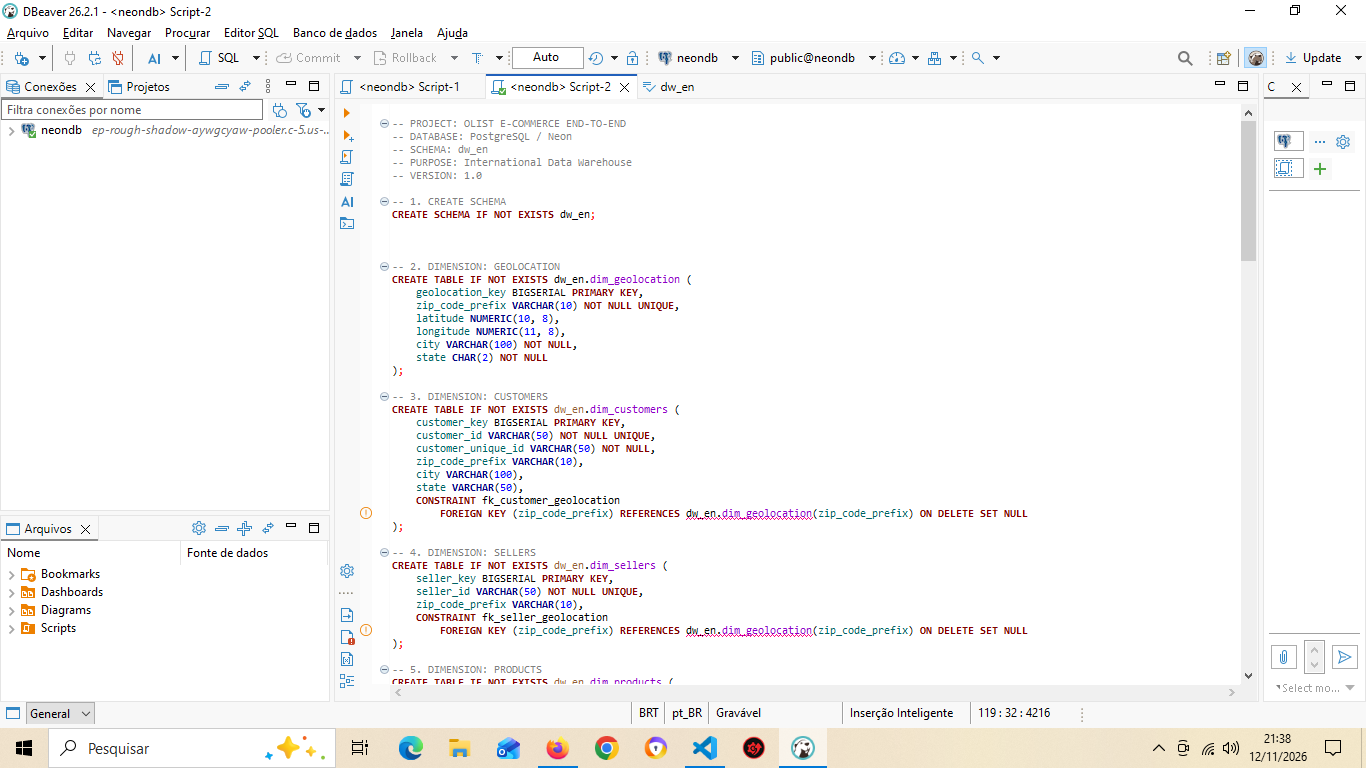

### Populando Tabelas no PostgreSQL Servless - NEON

In [126]:
from sqlalchemy import create_engine, text

In [127]:
# CRIANDO MOTOR DE CONEXÃO AO DATA WAREHOUSE POSTGRESQL USANDO SQLALCHEMY
engine = create_engine(os.getenv('DATABASE_URL'))

In [128]:
# Testando a conexão com o banco de dados
try:
    with engine.connect() as connection:
        result = connection.execute(text("SELECT version();"))
        print("Conexão bem-sucedida ao banco de dados! Versão do Postgres:")
        print(result.fetchone()[0])
except Exception as e:
    print(f"Erro ao conectar: {e}")

Conexão bem-sucedida ao banco de dados! Versão do Postgres:
PostgreSQL 18.7 (a21afb5) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit


In [129]:
# 1. Resetar o motor de conexão para garantir que nenhuma transação pendente trave o banco
engine.dispose()
# engine = create_engine(DATABASE_URL)

# 2. Executar o TRUNCATE em cascata para todas as tabelas do Data Warehouse
truncate_query = text("""
    TRUNCATE TABLE 
        dw_en.fact_sales, 
        dw_en.fact_payments, 
        dw_en.fact_reviews, 
        dw_en.dim_customers, 
        dw_en.dim_sellers, 
        dw_en.dim_products, 
        dw_en.dim_geolocation, 
        dw_en.dim_date 
    RESTART IDENTITY CASCADE;
""")

try:
    with engine.begin() as conn:
        conn.execute(truncate_query)
    print("Todas as tabelas do Data Warehouse foram limpas e os contadores (BIGSERIAL) resetados para 1!")
except Exception as e:
    print(f"Erro ao limpar as tabelas: {e}")

Todas as tabelas do Data Warehouse foram limpas e os contadores (BIGSERIAL) resetados para 1!


In [130]:
# Criando intervalo contínuos de datas para a tabela dim_calendario (2016 a 2020)
dates = pd.date_range(start='2016-01-01', end='2020-12-31', freq='D')

df_date = pd.DataFrame({'data': dates})

In [131]:
# Extraindo atributos do calendário para o Data Warehouse

df_date['date_key'] = df_date['data'].dt.strftime('%Y%m%d').astype('Int64')

df_date['full_date'] = pd.to_datetime(df_date['data']).dt.date

df_date['year'] = df_date['data'].dt.year
df_date['month'] = df_date['data'].dt.month
df_date['month_name'] = df_date['data'].dt.strftime('%B')
df_date['day'] = df_date['data'].dt.day
df_date['day_of_week'] = df_date['data'].dt.dayofweek + 1
df_date['day_name'] = df_date['data'].dt.strftime('%A')
df_date['quarter'] = df_date['data'].dt.quarter
df_date['is_weekend'] = df_date['day_of_week'].isin([6, 7])

In [132]:
df_date_dw = df_date[[
    'date_key',
    'full_date',
    'year',
    'month',
    'month_name',
    'day',
    'day_of_week',
    'day_name',
    'quarter',
    'is_weekend'
]].copy()

In [133]:
engine.dispose()

### Inserindo a tabela calendario no Neon

In [134]:
# inserir no postgresql neon Dim_calendario
try:
    df_date_dw.to_sql(name='dim_date', con=engine, schema='dw_en', if_exists='append', index=False, method='multi', chunksize=1000)
    print("Dimensão Calendário inserida com sucesso!")
except Exception as e:
    print(f"Erro ao popular dim_calendario: {e}")

Dimensão Calendário inserida com sucesso!


In [135]:
# 1. Resetar a conexão para destravar o banco de dados
engine.dispose()

### Inserindo Geolocation no Data Warehouse Neon

In [136]:
# POPULANDO DIM_GEOLOCALIZACAO NO POSTGRESQL NEON

try:
    geolocation.to_sql(name='dim_geolocation', con=engine, schema='dw_en', if_exists='append', index=False, method='multi', chunksize=1000)
    print("Dimensão Geolocalização inserida com sucesso!")
except Exception as e:
    print(f"Erro ao popular dim_geolocalizacao: {e}")

Dimensão Geolocalização inserida com sucesso!


### Insert data in Data warehouse Neon table Products

In [137]:
# POPULAR TABELA PRODUTOS
# 3. Enviar para o PostgreSQL Neon
try:
    products_dw.to_sql(name='dim_products', con=engine, schema='dw_en', if_exists='append', index=False, method='multi', chunksize=1000)
    print("Tabela dim_products inserida com sucesso!")

except Exception as e:
    print(f"Erro ao popular dim_produtos: {e}")

Tabela dim_products inserida com sucesso!


### Ao popular a tabela clientes foi constatado que haviam cep inexistentes em geolocalizacao e foi tratado abaixo com busca pela API pub. VIACEP:

In [138]:
import time
import requests

In [139]:
# Identifica os CEPs únicos de clientes que NÃO existem na geolocalização
missing_zip_code_prefixes = customers[~customers["zip_code_prefix"].isin(geolocation["zip_code_prefix"])]["zip_code_prefix"].unique()

print(f"Total de CEPs ausentes identificados: {len(missing_zip_code_prefixes)}")

Total de CEPs ausentes identificados: 157


In [140]:
#listar ceps ausentes
print("CEPs ausentes:")
for cep in missing_zip_code_prefixes:
    print(cep)

CEPs ausentes:
72300
11547
64605
72465
07729
72904
35408
78554
73369
08980
29949
65137
28655
73255
28388
06930
71676
64047
61906
83210
71919
36956
35242
72005
29718
41347
70324
70686
72341
12332
70716
71905
75784
73082
71884
71574
72238
71996
76968
71975
72595
72017
72596
67105
25840
72002
72821
85118
25919
95853
72583
68511
70701
71591
72535
95572
73090
72242
86135
70316
73091
41098
58734
73310
71810
72280
07430
73081
70333
72268
35104
72455
72237
17390
76897
84623
70702
72760
73088
29196
36596
57254
71995
73093
75257
48504
83843
62625
37005
73401
49870
13307
28617
73402
56327
71976
72587
85958
19740
77404
44135
28120
72863
87323
87511
72440
72243
65830
71261
28575
02140
71551
72023
28160
55027
43870
94370
38710
42716
36248
71593
71953
72549
72457
56485
71590
93602
07412
08342
39103
72536
59547
59299
85894
36857
71993
07784
71539
42843
86996
73272
72867
27980
58286
71208
71971
73391
64095
72427
38627
62898
71698
12770
72338
68629
28530
55863


In [141]:
new_records = []

In [142]:
# Iteracao sobre cada prefixo ausente
for i, cep in enumerate(missing_zip_code_prefixes, start=1):
    # O ViaCEP exige 8 dígitos. Completamos com '000' para buscar o CEP base da região/rua
    cep_busca = f"{cep}000"
    url = f"https://viacep.com.br/ws/{cep_busca}/json/"

    city = "Unknown"
    state = "ND"

    try:
        response = requests.get(url, timeout=3)
        if response.status_code == 200:
            dados = response.json()
            # Se a API encontrar o CEP completo ou a faixa genérica da cidade
            if "erro" not in dados:
                city = dados.get("locality", "Unknown")
                state = dados.get("uf", "ND")
    except Exception:
        pass  # Em caso de falha de conexão ou timeout, mantém os valores padrão

    new_records.append(
        {
            "zip_code_prefix": cep,
            "latitude": None,
            "longitude": None,
            "city": city,
            "state": state,
        }
    )

    # Exibe progresso a cada 20 requisições para acompanhar a execução
    if i % 20 == 0 or i == len(missing_zip_code_prefixes):
        print(f"Processados {i}/{len(missing_zip_code_prefixes)} CEPs...")

    # Pausa leve de 0.05s para respeitar os limites de taxa da API pública
    time.sleep(0.05)

# 3. Converte os dados buscados em DataFrame
df_zip_code_prefix_new = pd.DataFrame(new_records)

Processados 20/157 CEPs...
Processados 40/157 CEPs...
Processados 60/157 CEPs...
Processados 80/157 CEPs...
Processados 100/157 CEPs...
Processados 120/157 CEPs...
Processados 140/157 CEPs...
Processados 157/157 CEPs...


In [143]:
df_zip_code_prefix_new.head()

,zip_code_prefix,latitude,longitude,city,state
0,72300,None,None,Unknown,ND
1,11547,None,None,Unknown,SP
2,64605,None,None,Unknown,PI
3,72465,None,None,Unknown,ND
4,07729,None,None,Unknown,SP


In [144]:
# contar a quantidade de cep com cidade "desconhecido"
df_zip_code_prefix_new[df_zip_code_prefix_new['city'] == 'Unknown'].shape[0]

157

In [145]:
# substituir none em latidude e longitude por "00000"
df_zip_code_prefix_new['latitude'] = df_zip_code_prefix_new['latitude'].fillna("00000")
df_zip_code_prefix_new['longitude'] = df_zip_code_prefix_new['longitude'].fillna("00000")

In [146]:
df_zip_code_prefix_new.head(10)

,zip_code_prefix,latitude,longitude,city,state
0,72300,00000,00000,Unknown,ND
1,11547,00000,00000,Unknown,SP
2,64605,00000,00000,Unknown,PI
3,72465,00000,00000,Unknown,ND
4,07729,00000,00000,Unknown,SP
5,72904,00000,00000,Unknown,GO
6,35408,00000,00000,Unknown,ND
7,78554,00000,00000,Unknown,MT
8,73369,00000,00000,Unknown,ND
9,08980,00000,00000,Unknown,SP


In [147]:
# 4. Normaliza os textos de cidade e estado
df_zip_code_prefix_new['city'] = df_zip_code_prefix_new['city'].apply(normalizar_texto)
df_zip_code_prefix_new['state'] = df_zip_code_prefix_new['state'].apply(normalizar_texto)

In [148]:
#transformar tudo em string e remover espaços extras
df_zip_code_prefix_new['city'] = df_zip_code_prefix_new['city'].astype(str).str.strip().str.slice(0, 100)
df_zip_code_prefix_new['state'] = df_zip_code_prefix_new['state'].astype(str).str.strip().str.upper().str.slice(0, 2)
df_zip_code_prefix_new['zip_code_prefix'] = df_zip_code_prefix_new['zip_code_prefix'].astype(str).str.zfill(5)

In [149]:
#Transformar latitude e longitude em float
df_zip_code_prefix_new['latitude'] = df_zip_code_prefix_new['latitude'].astype(float)
df_zip_code_prefix_new['longitude'] = df_zip_code_prefix_new['longitude'].astype(float)

In [150]:
# rodando rollback
engine.dispose()  # Limpa o pool de conexões e reseta as sessões pendentes

In [151]:
# 3. Enviar SOMENTE os novos para a tabela do PostgreSQL
df_zip_code_prefix_new.to_sql(
    name='dim_geolocation',
    con=engine,
    schema='dw_en',
    if_exists='append',  # Adiciona os novos registros ao final da tabela
    index=False
)

-1

### Uma vez adicionado os CEPs ausentes é possível popular a tabela dim_clientes

In [152]:
# Popular tabela clientes
# 3. Enviar para o PostgreSQL Neon
try:    
    customers.to_sql('dim_customers', con=engine, schema='dw_en', if_exists='append', index=False, method='multi', chunksize=1000)
    print("Dimensão Clientes inserida com sucesso!")

except Exception as e:
    print(f"Erro ao popular dim_clientes: {e}")

Dimensão Clientes inserida com sucesso!


In [153]:
# Conferindo total de registros em geolocalizacao com os novos registros de ceps
geolocalizacao2 = pd.concat([geolocation, df_zip_code_prefix_new], ignore_index=True)
print(f"Total de registros na tabela dim_geolocation após a inserção: {geolocalizacao2.shape[0]}")

Total de registros na tabela dim_geolocation após a inserção: 19172


### populando a tabela dim_Sellers

In [154]:
engine.dispose()

In [155]:
# 1. Buscar os CEPs já gravados no banco
with engine.connect() as conn:
    zip_code_dw = pd.read_sql("SELECT DISTINCT zip_code_prefix FROM dw_en.dim_geolocation;", con=conn)
engine.dispose()

In [156]:
sellers.head()

,seller_id,zip_code_prefix,city,state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,sp
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,sp
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,rj
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,sp
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,sp


In [157]:
# 2. Garantir formato de 5 dígitos nos CEPs dos vendedores
sellers['zip_code_prefix'] = sellers['zip_code_prefix'].astype(str).str.zfill(5)

In [158]:
# 3. Descobrir os CEPs dos vendedores que NÃO estão no DW
zip_code_sellers = set(sellers['zip_code_prefix'].dropna().unique())
zip_code_exist = set(zip_code_dw['zip_code_prefix'])
missing_zip_code = zip_code_sellers - zip_code_exist

print(f"Total de CEPs de vendedores ausentes na dim_geolocation: {len(missing_zip_code)}")

Total de CEPs de vendedores ausentes na dim_geolocation: 5


In [159]:
#  Buscar informações via ViaCEP para os CEPs faltantes
zip_code_new = []
total_faltantes = len(missing_zip_code)

for i, zip_code in enumerate(missing_zip_code, start=1):
    cep_busca = f"{str(zip_code).zfill(5)}000"
    url = f"https://viacep.com.br/ws/{cep_busca}/json/"
    
    cidade = "unknown"
    estado = "ND"
    
    try:
        response = requests.get(url, timeout=3)
        if response.status_code == 200:
            dados = response.json()
            if "erro" not in dados:
                cidade = dados.get("localidade", "unknown").lower()
                estado = dados.get("uf", "ND")
    except Exception:
        pass
    
    zip_code_new.append({
        "zip_code_prefix": zip_code,
        "latitude": None,
        "longitude": None,
        "city": city,
        "state": state
    })

    # Exibe progresso a cada 20 requisições
    if i % 20 == 0 or i == total_faltantes:
        print(f"Processados {i}/{total_faltantes} CEPs...")
    
    # Pausa leve para respeitar o rate-limit da API pública
    time.sleep(0.05)

# 5. Converte os dados buscados em DataFrame
df_zip_code_prefix_new3 = pd.DataFrame(zip_code_new)

Processados 5/5 CEPs...


In [160]:
df_zip_code_prefix_new3.head()

,zip_code_prefix,latitude,longitude,city,state
0,02285,None,None,Unknown,PE
1,91901,None,None,Unknown,PE
2,37708,None,None,Unknown,PE
3,82040,None,None,Unknown,PE
4,72580,None,None,Unknown,PE


In [161]:
# substituir none em latidude e longitude por "00000"
df_zip_code_prefix_new3['latitude'] = df_zip_code_prefix_new3['latitude'].fillna("00000")
df_zip_code_prefix_new3['longitude'] = df_zip_code_prefix_new3['longitude'].fillna("00000")

In [162]:
# Normaliza os textos de cidade e estado
df_zip_code_prefix_new3['city'] = df_zip_code_prefix_new3['city'].apply(normalizar_texto)
df_zip_code_prefix_new3['state'] = df_zip_code_prefix_new3['state'].apply(normalizar_texto)

In [163]:
#transformar tudo em string e remover espaços extras
df_zip_code_prefix_new3['city'] = df_zip_code_prefix_new3['city'].astype(str).str.strip().str.slice(0, 100)
df_zip_code_prefix_new3['state'] = df_zip_code_prefix_new3['state'].astype(str).str.strip().str.upper().str.slice(0, 2)
df_zip_code_prefix_new3['zip_code_prefix'] = df_zip_code_prefix_new3['zip_code_prefix'].astype(str).str.zfill(5)

In [164]:
#Transformar latitude e longitude em float
df_zip_code_prefix_new3['latitude'] = df_zip_code_prefix_new3['latitude'].astype(float)
df_zip_code_prefix_new3['longitude'] = df_zip_code_prefix_new3['longitude'].astype(float)

In [165]:
df_zip_code_prefix_new3.head(10)

,zip_code_prefix,latitude,longitude,city,state
0,02285,0.0,0.0,unknown,PE
1,91901,0.0,0.0,unknown,PE
2,37708,0.0,0.0,unknown,PE
3,82040,0.0,0.0,unknown,PE
4,72580,0.0,0.0,unknown,PE


In [166]:
# 3. Enviar SOMENTE os novos para a tabela do PostgreSQL
df_zip_code_prefix_new3.to_sql(
    name='dim_geolocation',
    con=engine,
    schema='dw_en',
    if_exists='append',  # Adiciona os novos registros ao final da tabela
    index=False
)

-1

In [167]:
sellers.head()

,seller_id,zip_code_prefix,city,state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,sp
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,sp
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,rj
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,sp
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,sp


In [168]:
# selecionando as colunas para a tabela
df_sellers_dw = sellers[[
    'seller_id',
    'zip_code_prefix',
]].copy()

In [169]:
engine.dispose()

In [170]:
# popular tabela dim_vendedores
try:
    df_sellers_dw.to_sql('dim_sellers', con=engine, schema='dw_en', if_exists='append', index=False, method='multi', chunksize=1000)
    print("Dimensão dim_sellers inserida com sucesso!")
except Exception as e:
    print(f"Erro ao popular dim_sellers: {e}")

Dimensão dim_sellers inserida com sucesso!


### Inserting table fact_sales

In [171]:
engine.dispose()

In [172]:
# 1. Carregar as dimensões do DW com suas Chaves de Negócio

with engine.connect() as conn:
    dim_date = pd.read_sql("SELECT date_key, full_date FROM dw_en.dim_date;", con=engine)

In [173]:
# garantir o formato correto para date
dim_date['full_date'] = pd.to_datetime(dim_date['full_date']).dt.normalize()

In [174]:
sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17


In [175]:
# 2. Relacionar as datas de vendas às chaves da dimensão calendário
for coluna_data, coluna_sk in [
    ('order_purchase_timestamp', 'order_date_key'),
    ('order_delivered_customer_date', 'delivery_date_key'),
    ('order_estimated_delivery_date', 'estimated_delivery_date_key')
]:

    sales[coluna_data] = pd.to_datetime(
        sales[coluna_data],
        errors='coerce'
    ).dt.normalize()

    sales = sales.merge(
        dim_date[['full_date', 'date_key']],
        left_on=coluna_data,
        right_on='full_date',
        how='left',
        validate='many_to_one'
    ).rename(
        columns={'date_key': coluna_sk}
    ).drop(
        columns='full_date'
    )

In [176]:
sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_date_key,delivery_date_key,estimated_delivery_date_key
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20,2017-09-29,20170913,20170920.0,20170929
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12,2017-05-15,20170426,20170512.0,20170515
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22,2018-02-05,20180114,20180122.0,20180205
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14,2018-08-20,20180808,20180814.0,20180820
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01,2017-03-17,20170204,20170301.0,20170317


In [177]:
# convertendo para INT
colunas_sk = [
    'order_date_key',
    'delivery_date_key',
    'estimated_delivery_date_key'
]

sales[colunas_sk] = sales[colunas_sk].astype('Int64')

In [178]:
print(sales.dtypes)

order_id                                    str
order_item_id                             int64
product_id                                  str
seller_id                                   str
shipping_limit_date              datetime64[us]
price                                   float64
freight_value                           float64
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
order_date_key                            Int64
delivery_date_key                         Int64
estimated_delivery_date_key               Int64
dtype: object


In [179]:
engine.dispose()

In [180]:
# Buscar as chaves da dimensão clientes
customer = pd.read_sql(
    """
    SELECT
        customer_key,
        customer_id
    FROM dw_en.dim_customers
    """,
    con=engine
)

In [181]:
# Dimensão dim_sellers
dim_vendedores = pd.read_sql(
    """
    SELECT seller_id, seller_key
    FROM dw_en.dim_sellers
    """,
    con=engine
)

In [182]:
# Dimensão dim_products
dim_produtos = pd.read_sql(
    """
    SELECT product_id, product_key
    FROM dw_en.dim_products
    """,
    con=engine
)

In [183]:
# removendo eventuais sk's
#vendas = vendas.drop(columns=['sk_cliente', 'sk_vendedor', 'sk_produto'], errors='ignore')

In [184]:
# Relacionamento entre clientes e vendas
sales = sales.merge(
    customer[['customer_id', 'customer_key']],
    on='customer_id',
    how='left',
    validate='many_to_one'
)

In [185]:
engine.dispose()

In [186]:
#buscando chaves de sellers no neon para relacionar com a fact_sales
seller = pd.read_sql(
    """
    SELECT
        seller_id,
        seller_key
    FROM dw_en.dim_sellers
    """,
    con=engine
)

In [187]:
# Relacionamento sales e sellers
sales = sales.merge(
    seller[['seller_id', 'seller_key']],
    on='seller_id',
    how='left',
    validate='many_to_one'
)

In [188]:
# Buscando chaves de products para relacionar com sales
product = pd.read_sql(
    """
    SELECT
        product_id,
        product_key
    FROM dw_en.dim_products
    """,
    con=engine
)

In [189]:
# Relacionamento Produtos
sales = sales.merge(
    product[['product_id', 'product_key']],
    on='product_id',
    how='left',
    validate='many_to_one'
)

### Retomando SKs de entrega

In [190]:
# Criando mapa de relacionamento
map_date = dim_date.set_index('full_date')['date_key']

In [191]:
# Removendo SKs de datas de entrega para recriá-las
sales = sales.drop(
    columns=[
        'delivery_date_key',
        'estimated_delivery_date_key'
    ],
    errors='ignore'
)

In [192]:
# Recuperar a chave da data de entrega real
sales['delivery_date_key'] = (
    pd.to_datetime(sales['order_delivered_customer_date'])
    .dt.normalize()
    .map(map_date)
    .astype('Int64')
)

In [193]:
# Remover chaves de datas anteriores, caso existam
sales = sales.drop(
    columns=[
        'delivery_date_key',
        'estimated_delivery_date_key'
    ],
    errors='ignore'
)

# Recuperar chave da data de entrega real
sales['delivery_date_key'] = (
    pd.to_datetime(sales['order_delivered_customer_date'])
    .dt.normalize()
    .map(map_date)
    .astype('Int64')
)

# Recuperar chave da data de entrega prevista
sales['estimated_delivery_date_key'] = (
    pd.to_datetime(sales['order_estimated_delivery_date'])
    .dt.normalize()
    .map(map_date)
    .astype('Int64')
)

In [194]:
# Validar os relacionamentos com a dimensão calendário

for data, sk in [
    ('order_delivered_customer_date', 'delivery_date_key'),
    ('order_estimated_delivery_date', 'estimated_delivery_date_key')
]:

    datas_sem_sk = sales.loc[
        sales[data].notna() & sales[sk].isna()
    ]

    print(f'\nRelacionamento: {data} -> {sk}')
    print('Datas originais nulas:', sales[data].isna().sum())
    print('SKs nulas:', sales[sk].isna().sum())
    print('Datas sem correspondência no calendário:', len(datas_sem_sk))


Relacionamento: order_delivered_customer_date -> delivery_date_key
Datas originais nulas: 2454
SKs nulas: 2454
Datas sem correspondência no calendário: 0

Relacionamento: order_estimated_delivery_date -> estimated_delivery_date_key
Datas originais nulas: 0
SKs nulas: 0
Datas sem correspondência no calendário: 0


In [195]:
#renomeando colunas
sales = sales.rename(columns={
    'order_delivered_carrier_date': 'shipped_at',
    'order_delivered_customer_date': 'delivered_at',
    'order_estimated_delivery_date': 'estimated_delivery_date'
})

In [196]:
# Organizando o DataFrame para inserir na fact_sales

colunas_fact_sales = [
    'order_id',
    'order_item_id',
    'customer_key',
    'seller_key',
    'product_key',
    'order_date_key',
    'delivery_date_key',
    'estimated_delivery_date_key',
    'order_status',
    'price',
    'freight_value',
    'shipping_limit_date',
    'order_approved_at',
    'shipped_at',
    'delivered_at',
    'estimated_delivery_date',
    'order_purchase_timestamp'
]

sales = sales[colunas_fact_sales].copy()

In [197]:
engine.dispose()

In [198]:
# Popular fact_sales no PostgreSQL Neon
try:
    sales.to_sql(
        name='fact_sales',
        con=engine,
        schema='dw_en',
        if_exists='append',
        index=False,
        method='multi',
        chunksize=1000
    )

    print("Tabela fact_sales populada com sucesso!")

except Exception as e:
    print(f"Erro ao popular fact_sales: {e}")

Tabela fact_sales populada com sucesso!


### Populando fato_pagamentos

In [205]:
engine.dispose()

In [206]:
# Carregar as dimensões necessárias do DW

with engine.connect() as conn:
    dim_customers = pd.read_sql("SELECT customer_key, customer_id FROM dw_en.dim_customers;", con=conn)
    dim_date = pd.read_sql("SELECT date_key, full_date FROM dw_en.dim_date;", con=conn)

In [208]:
# Buscar os pedidos e suas chaves substitutas diretamente no Neon
orders = pd.read_sql("""
    SELECT DISTINCT
        order_id,
        customer_key,
        order_purchase_timestamp
    FROM dw_en.fact_sales
""", con=engine)

In [209]:
# Preparar tipos de dados

dim_date['full_date'] = pd.to_datetime(dim_date['full_date']).dt.date
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

In [210]:
# Criar coluna auxiliar para relacionamento com calendário

orders['order_date'] = (orders['order_purchase_timestamp'].dt.date)

In [211]:
# Verificar integridade dos pedidos

print("Total de registros:", len(orders))
print("Pedidos distintos:", orders['order_id'].nunique())
print("Pedidos duplicados:", orders['order_id'].duplicated().sum())
print("Datas de compra nulas:", orders['order_purchase_timestamp'].isna().sum())
print(orders.head())

Total de registros: 98666


Pedidos distintos: 98666
Pedidos duplicados: 0
Datas de compra nulas: 0
                           order_id  customer_key order_purchase_timestamp  \
0  15c6ed2642d0ed7b492597fffca4d9a6         41123               2017-12-23   
1  c8da096eda1ac468af162c20d2621512         72054               2017-09-20   
2  79bdeae310789e415e342ede8f9ad5f5         86894               2017-11-22   
3  455dbd3c7fa4666ddb7b723bbdd09076         77276               2018-07-16   
4  b552361bfa71f85d48c308d95c713f23         80576               2017-11-08   

   order_date  
0  2017-12-23  
1  2017-09-20  
2  2017-11-22  
3  2018-07-16  
4  2017-11-08  


In [ ]:
# criando relacionamento coma dimensão calendario
orders = orders.merge(dim_date, left_on='order_date', right_on='full_date', how='left', indicator=True)

In [ ]:
# Verificar correspondências

print("Pedidos encontrados:", (orders['_merge'] == 'both').sum())
print("Pedidos sem correspondência:", (orders['_merge'] == 'left_only').sum())
print("SKs de data nulas:", orders['date_key'].isna().sum())

Pedidos encontrados: 98666
Pedidos sem correspondência: 0
SKs de data nulas: 0


In [ ]:
# Identificar pedidos sem correspondência

orders_without_date = orders[orders['_merge'] == 'left_only'].copy()
print(orders_without_date.head())

Empty DataFrame
Columns: [order_id, customer_key, order_purchase_timestamp, order_date, date_key, full_date, _merge]
Index: []


In [217]:
# Relacionar pagamentos com pedidos

payments_merged = payment.merge(orders[['order_id', 'customer_key', 'date_key']],on='order_id', how='left',
    indicator=True
)

In [218]:

# Identificar pagamentos sem correspondência

payments_without_order = payments_merged[payments_merged['_merge'] == 'left_only'].copy()

print("Total de pagamentos:", len(payment))

print("Pagamentos sem correspondência:", len(payments_without_order))

print("Pedidos distintos sem correspondência:", payments_without_order['order_id'].nunique())

print(payments_without_order.head(10))


Total de pagamentos: 103886
Pagamentos sem correspondência: 830
Pedidos distintos sem correspondência: 775
                              order_id  payment_sequential payment_type  \
68    947e9c6bfd83a06953c420ef92d3da6e                   1      voucher   
235   f86d7bc39aab05299691322044b63bb2                   1      voucher   
259   90eaac01afdf4e531a70ad869e092c75                   1  credit_card   
720   fe87d4b944748f63ca5ed22cc55b6fb6                   1   debit_card   
1014  4a42846a6eed9d15714fe30181399f2a                   1  credit_card   
1028  27667a063cb59b5d987a5a71c192cce5                   1      voucher   
1086  6ad57aecbae806a7e9cc2cdb6b380711                   1  credit_card   
1095  572c4bbf0f5f85a9b4a2c4fe0c7f04d5                   1      voucher   
1267  98fe01bc254b759c1f2c11d77c2891d5                   1      voucher   
1307  52267d8c7f4a0227294efd0ef23fcefb                   1  credit_card   

      payment_installments  payment_value  customer_key  date_key  

In [ ]:
# Verificar quais pedidos sem correspondência na fact_sales
# existem no DataFrame original de pedidos

missing_order_ids = payments_without_order['order_id'].unique()

orders_original_check = order[order['order_id'].isin(missing_order_ids)]

print("Pedidos encontrados na origem:", orders_original_check['order_id'].nunique())

print("Pedidos não encontrados na origem:", len(set(missing_order_ids) -
          set(orders_original_check['order_id'])))

Pedidos encontrados na origem: 775
Pedidos não encontrados na origem: 0


In [ ]:
# Identificar pedidos sem correspondência na fact_sales
missing_order_ids = payments_without_order['order_id'].unique()

# Verificar quais desses pedidos possuem itens
items_check = item[item['order_id'].isin(missing_order_ids)]

print("Pedidos com itens:", items_check['order_id'].nunique())

print("Total de linhas de itens:", len(items_check))

print("Pedidos sem itens:", len(set(missing_order_ids) -
          set(items_check['order_id'])))

Pedidos com itens: 0
Total de linhas de itens: 0
Pedidos sem itens: 775


In [222]:
orders = order[
    [
        'order_id',
        'customer_id',
        'order_purchase_timestamp'
    ]
].drop_duplicates(subset=['order_id']).copy()

print("Pedidos na origem:", len(orders))
print("Pedidos distintos:", orders['order_id'].nunique())
print(orders.head())

Pedidos na origem: 99441
Pedidos distintos: 99441
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_purchase_timestamp  
0      2017-10-02 10:56:33  
1      2018-07-24 20:41:37  
2      2018-08-08 08:38:49  
3      2017-11-18 19:28:06  
4      2018-02-13 21:18:39  


In [223]:
engine.dispose()

In [ ]:
# Buscar a dimensão de clientes
customer = pd.read_sql("""
    SELECT
        customer_id,
        customer_key
    FROM dw_en.dim_customers
""", con=engine)

# Relacionar os pedidos com a dimensão de clientes
orders = orders.merge(customer, on='customer_id', how='left', validate='many_to_one', indicator=True)

# Verificar correspondências
print("Pedidos sem customer_key:", (orders['_merge'] == 'left_only').sum())

print(orders.head())

Pedidos sem customer_key: 0
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_purchase_timestamp  customer_key _merge  
0      2017-10-02 10:56:33         70297   both  
1      2018-07-24 20:41:37         77028   both  
2      2018-08-08 08:38:49           555   both  
3      2017-11-18 19:28:06         61082   both  
4      2018-02-13 21:18:39         67264   both  


In [ ]:
# Normalizar a data de compra
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'],errors='coerce'
).dt.normalize()

# Buscar a dimensão calendário
dim_date = pd.read_sql("""
    SELECT
        date_key,
        full_date
    FROM dw_en.dim_date
""", con=engine)

# Normalizar a data da dimensão calendário
dim_date['full_date'] = pd.to_datetime(dim_date['full_date']).dt.normalize()

# Criar o mapeamento entre data e chave substituta
map_date = dim_date.set_index('full_date')['date_key']

# Obter order_date_key
orders['order_date_key'] = (orders['order_purchase_timestamp'].map(map_date))

# Validar
print("Pedidos sem order_date_key:", orders['order_date_key'].isna().sum())

print(orders[['order_id', 'customer_key', 'order_date_key']].head())

Pedidos sem order_date_key: 0
                           order_id  customer_key  order_date_key
0  e481f51cbdc54678b7cc49136f2d6af7         70297        20171002
1  53cdb2fc8bc7dce0b6741e2150273451         77028        20180724
2  47770eb9100c2d0c44946d9cf07ec65d           555        20180808
3  949d5b44dbf5de918fe9c16f97b45f8a         61082        20171118
4  ad21c59c0840e6cb83a9ceb5573f8159         67264        20180213


In [226]:
# Remover coluna auxiliar da validação anterior
orders_ready = orders.drop(columns=['_merge']).copy()

# Cruzar pagamentos com os pedidos e suas chaves substitutas
payments_merged = payment.merge(
    orders_ready[
        [
            'order_id',
            'customer_key',
            'order_date_key'
        ]
    ],
    on='order_id',
    how='left',
    validate='many_to_one',
    indicator=True
)

# Validar correspondências
unmatched = payments_merged[
    payments_merged['_merge'] == 'left_only'
]

print("Total de pagamentos:", len(payments_merged))
print("Pagamentos sem pedido correspondente:", len(unmatched))
print("Pedidos distintos nos pagamentos:",
      payments_merged['order_id'].nunique())

Total de pagamentos: 103886
Pagamentos sem pedido correspondente: 0
Pedidos distintos nos pagamentos: 99440


In [227]:
# Remover coluna auxiliar do merge
payments_merged.drop(columns=['_merge'], inplace=True)

# Verificar valores nulos
print("Valores nulos:")
print(payments_merged[
    [
        'order_id',
        'customer_key',
        'order_date_key',
        'payment_sequential',
        'payment_type',
        'payment_installments',
        'payment_value'
    ]
].isnull().sum())

# Verificar duplicidade na granularidade da fato
duplicates = payments_merged.duplicated(
    subset=['order_id', 'payment_sequential']
).sum()

print("\nPagamentos duplicados:", duplicates)

# Verificar quantidade de registros
print("Total de registros:", len(payments_merged))

Valores nulos:
order_id                0
customer_key            0
order_date_key          0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Pagamentos duplicados: 0
Total de registros: 103886


In [230]:
payment.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:
# Selecionar exatamente as colunas do DDL
columns_fact_payments = [
    'order_id',
    'customer_key',
    'order_date_key',
    'payment_sequential',
    'payment_type',
    'payment_installments',
    'payment_value'
]

fact_payments_ready = payments_merged[columns_fact_payments].copy()

print(fact_payments_ready.head())
engine.dispose()
print(fact_payments_ready.shape)

                           order_id  customer_key  order_date_key  \
0  b81ef226f3fe1789b1e8b2acac839d17         49653        20180425   
1  a9810da82917af2d9aefd1278f1dcfa0         75027        20180626   
2  25e8ea4e93396b6fa0d3dd708e76c1bd         26281        20171212   
3  ba78997921bbcdc1373bb41e913ab953         77779        20171206   
4  42fdf880ba16b47b59251dd489d4441a         13913        20180521   

   payment_sequential payment_type  payment_installments  payment_value  
0                   1  credit_card                     8          99.33  
1                   1  credit_card                     1          24.39  
2                   1  credit_card                     1          65.71  
3                   1  credit_card                     8         107.78  
4                   1  credit_card                     2         128.45  
(103886, 7)


In [229]:
#verificando registros existentes
existing_payments = pd.read_sql("""
    SELECT COUNT(*) AS total
    FROM dw_en.fact_payments
""", con=engine)

print("Registros existentes:",
      existing_payments['total'].iloc[0])

Registros existentes: 0


In [232]:
engine.dispose()

In [233]:
try:
    with engine.begin() as conn:
        fact_payments_ready.to_sql(
            name='fact_payments',
            con=conn,
            schema='dw_en',
            if_exists='append',
            index=False,
            method='multi',
            chunksize=1000
        )

    print(
        f"Fact Payments populada com sucesso! "
        f"({len(fact_payments_ready)} registros)"
    )

except Exception as e:
    print(f"Erro ao inserir Fact Payments: {e}")

Fact Payments populada com sucesso! (103886 registros)


### Populando fato_avaliacao

In [ ]:
engine.dispose()

In [234]:
# Buscar a dimensão de clientes diretamente no Neon
dim_customers = pd.read_sql("""
    SELECT
        customer_id,
        customer_key
    FROM dw_en.dim_customers
""", con=engine)

In [ ]:
# Preparar os pedidos originais
orders_reviews = orders[['order_id', 'customer_id']].drop_duplicates(subset=['order_id']).copy()

In [236]:

# Relacionar pedidos com clientes
orders_reviews = orders_reviews.merge(dim_customers, left_on='customer_id', right_on='customer_id',
    how='left',
    validate='many_to_one',
    indicator=True
)

print("Pedidos sem customer_key:", (orders_reviews['_merge'] == 'left_only').sum())

orders_reviews.drop(columns=['customer_id', '_merge'], inplace=True)

Pedidos sem customer_key: 0


In [238]:
# Remover duplicidades de avaliação pelo identificador
reviews_temp = review.drop_duplicates(subset=['review_id']).copy()

In [239]:
# Relacionar avaliações com os pedidos
reviews_merged = reviews_temp.merge(orders_reviews[['order_id', 'customer_key']],
    on='order_id',
    how='left',
    validate='many_to_one',
    indicator=True
)

In [240]:
# Verificar avaliações sem pedido correspondente
print("Avaliações sem pedido correspondente:", (reviews_merged['_merge'] == 'left_only').sum())

reviews_merged.drop(columns=['_merge'], inplace=True)

Avaliações sem pedido correspondente: 0


In [242]:
engine.dispose()

In [243]:
# Buscar dimensão calendário no Neon
dim_date = pd.read_sql("""
    SELECT
        date_key,
        full_date
    FROM dw_en.dim_date
""", con=engine)

In [245]:
# Converter timestamps
reviews_merged['review_answer_timestamp'] = pd.to_datetime(reviews_merged['review_answer_timestamp'],
    errors='coerce')

reviews_merged['review_creation_date'] = pd.to_datetime(reviews_merged['review_creation_date'], errors='coerce')

In [246]:
# Normalizar datas para relacionamento com o calendário
dim_date['full_date'] = pd.to_datetime(dim_date['full_date']).dt.normalize()

In [247]:
# Criar mapeamento da data para a chave substituta
map_date = dim_date.set_index('full_date')['date_key']

In [248]:
# Obter a chave substituta da data de resposta
reviews_merged['review_answer_date_key'] = (reviews_merged['review_answer_timestamp'].dt.normalize()
    .map(map_date))

In [249]:
# Utilizar Int64 para permitir valores nulos
reviews_merged['review_answer_date_key'] = (reviews_merged['review_answer_date_key'].astype('Int64'))

In [250]:
reviews_merged.head(1)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,customer_key,review_answer_date_key
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,untitled,no description,2018-01-18,2018-01-18 21:46:59,44071,20180118


In [251]:
# Renomear os campos conforme o Data Warehouse
fact_reviews_ready = reviews_merged.rename(columns={
    'review_creation_date': 'review_created_at',
    'review_answer_timestamp': 'review_answered_at'
})

In [ ]:
# Selecionar exatamente as colunas da fact_reviews
columns_fact_reviews = [
    'review_id',
    'order_id',
    'customer_key',
    'review_answer_date_key',
    'review_score',
    'review_comment_title',
    'review_comment_message',
    'review_created_at',
    'review_answered_at'
]

fact_reviews_ready = fact_reviews_ready[columns_fact_reviews].copy()

In [253]:
# Verificar valores nulos
print("Valores nulos:")
print(fact_reviews_ready.isnull().sum())

Valores nulos:
review_id                 0
order_id                  0
customer_key              0
review_answer_date_key    0
review_score              0
review_comment_title      0
review_comment_message    0
review_created_at         0
review_answered_at        0
dtype: int64


In [254]:
# Verificar duplicidades de review_id
duplicates = fact_reviews_ready.duplicated(subset=['review_id']).sum()
print("\nAvaliações duplicadas:", duplicates)


Avaliações duplicadas: 0


In [255]:
# Verificar notas fora do intervalo permitido
print("Notas inválidas:", (~fact_reviews_ready['review_score'].between(1, 5)).sum())
print("\nTotal de avaliações:", len(fact_reviews_ready))
print(fact_reviews_ready.head())

Notas inválidas: 0

Total de avaliações: 98410
                          review_id                          order_id  \
0  7bc2406110b926393aa56f80a40eba40  73fc7af87114b39712e6da79b0a377eb   
1  80e641a11e56f04c1ad469d5645fdfde  a548910a1c6147796b98fdf73dbeba33   
2  228ce5500dc1d8e020d8d1322874b6f0  f9e4b658b201a9f2ecdecbb34bed034b   
3  e64fb393e7b32834bb789ff8bb30750e  658677c97b385a9be170737859d3511b   
4  f7c4243c7fe1938f181bec41a392bdeb  8e6bfb81e283fa7e4f11123a3fb894f1   

   customer_key  review_answer_date_key  review_score review_comment_title  \
0         44071                20180118             4             untitled   
1         92399                20180311             5             untitled   
2         30603                20180218             5             untitled   
3         70156                20170421             5             untitled   
4         64935                20180302             5             untitled   

                              review_comment_

In [256]:
engine.dispose()

In [258]:
# Inserção no PostgreSQL
try:
    with engine.begin() as conn:
        fact_reviews_ready.to_sql(
            'fact_reviews', 
            con=conn, 
            if_exists='append',
            schema='dw_en', 
            index=False, 
            method='multi', 
            chunksize=1000
        )
    print(f"Fato Avaliações populada com sucesso! ({len(fact_reviews_ready)} registros)")
except Exception as e:
    print(f"Erro ao inserir Fato Avaliações: {e}")

Fato Avaliações populada com sucesso! (98410 registros)


### Auditoria

In [288]:
# Consulta de Volumetria Geral
query_volumetry = """
SELECT 'dim_geolocation' AS tabela, COUNT(*) AS total_registros FROM dw_en.dim_geolocation
UNION ALL SELECT 'dim_customers', COUNT(*) FROM dw_en.dim_customers
UNION ALL SELECT 'dim_sellers', COUNT(*) FROM dw_en.dim_sellers
UNION ALL SELECT 'dim_products', COUNT(*) FROM dw_en.dim_products
UNION ALL SELECT 'dim_date', COUNT(*) FROM dw_en.dim_date
UNION ALL SELECT 'fact_sales', COUNT(*) FROM dw_en.fact_sales
UNION ALL SELECT 'fact_payments', COUNT(*) FROM dw_en.fact_payments
UNION ALL SELECT 'fact_reviews', COUNT(*) FROM dw_en.fact_reviews;
"""

In [260]:
order.head(1)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18


In [289]:

query_sales = """
SELECT
    COUNT(*) AS total_itens_vendidos,
    COUNT(DISTINCT order_id) AS pedidos_unicos,
    SUM(price) AS receita_produtos,
    SUM(freight_value) AS receita_frete,
    SUM(price + freight_value) AS receita_bruta_total,
    MIN(order_purchase_timestamp) AS primeira_venda,
    MAX(order_purchase_timestamp) AS ultima_venda
FROM dw_en.fact_sales;
"""


In [290]:
# 3. Auditoria Financeira na Fato Pagamentos
query_payments = """
SELECT 
    COUNT(*) AS total_transacoes,
    COUNT(DISTINCT order_id) AS pedidos_pagos_unicos,
    SUM(payment_value) AS total_pago
FROM dw_en.fact_payments;
"""

In [295]:
review.head(1)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,untitled,no description,2018-01-18,2018-01-18 21:46:59


In [296]:
# 4. Auditoria de Satisfação na Fato Avaliações
query_reviews = """
SELECT 
    COUNT(*) AS total_avaliacoes,
    ROUND(AVG(review_score), 2) AS media_notas,
    COUNT(review_answer_date_key) AS avaliacoes_respondidas
FROM dw_en.fact_reviews;
"""

In [297]:
engine.dispose()

In [298]:
with engine.connect() as conn:

    df_volumetria = pd.read_sql(query_volumetry, con=conn)

    df_aud_vendas = pd.read_sql(query_sales, con=conn)

    df_aud_pagamentos = pd.read_sql(query_payments, con=conn)

    df_aud_avaliacoes = pd.read_sql(query_reviews, con=conn)

In [299]:
# Executando todas as consultas no banco Neon
with engine.connect() as conn:
    df_volumetria = pd.read_sql(query_volumetry, con=conn)
    df_aud_vendas = pd.read_sql(query_sales, con=conn)
    df_aud_pagamentos = pd.read_sql(query_payments, con=conn)
    df_aud_avaliacoes = pd.read_sql(query_reviews, con=conn)

print("=== 1. VOLUMETRIA DAS TABELAS NO NEON ===")
display(df_volumetria)

print("\n=== 2. AUDITORIA FATO VENDAS ===")
display(df_aud_vendas)

print("\n=== 3. AUDITORIA FATO PAGAMENTOS ===")
display(df_aud_pagamentos)

print("\n=== 4. AUDITORIA FATO AVALIAÇÕES ===")
display(df_aud_avaliacoes)

=== 1. VOLUMETRIA DAS TABELAS NO NEON ===


,tabela,total_registros
0,dim_date,1827
1,dim_sellers,3095
2,dim_geolocation,19177
3,dim_products,32951
4,fact_reviews,98410
5,fact_payments,103886
6,dim_customers,99441
7,fact_sales,112650



=== 2. AUDITORIA FATO VENDAS ===


,total_itens_vendidos,pedidos_unicos,receita_produtos,receita_frete,receita_bruta_total,primeira_venda,ultima_venda
0,112650,98666,13591643.7,2251909.54,15843553.24,2016-09-04,2018-09-03



=== 3. AUDITORIA FATO PAGAMENTOS ===


,total_transacoes,pedidos_pagos_unicos,total_pago
0,103886,99440,16008872.12



=== 4. AUDITORIA FATO AVALIAÇÕES ===


,total_avaliacoes,media_notas,avaliacoes_respondidas
0,98410,4.09,98410
